# Employee Attrition Analysis (2006 – 2015)

**Business question:** *Who leaves the company, when do they leave, and why?*

A retail company (stores with departments such as Produce, Meats, Dairy and Customer Service) tracked every employee once per year from 2006 to 2015. In this notebook I clean that HR data with Python and Pandas, then analyse **attrition** (employees leaving the company) to find where HR should focus.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

### Roadmap

| Step | What I do | Why |
|---|---|---|
| 1 | Import libraries | Get the tools ready |
| 2 | Load and inspect the data | Understand what each row and column means |
| 3 | Clean the data | Remove duplicates, fix types, typos and misleading values |
| 4 | Analyse attrition | Who / when / where / why people leave |
| 5 | Conclusion | Findings, recommendations and limitations |

### How to run this notebook
Put `Attrition_dataset.csv` in the same folder as this notebook, then run all cells from top to bottom. The notebook saves two files for a Power BI dashboard: `Attrition_cleaned.csv` and `yearly_summary.csv`.

### Data dictionary

| Original column | New name | Meaning |
|---|---|---|
| `EmployeeID` | `id` | Unique employee number |
| `recorddate_key` | `record_date` | Date of this yearly snapshot |
| `birthdate_key` | `dob` | Date of birth |
| `orighiredate_key` | `hire_date` | Original hire date |
| `terminationdate_key` | `term_date` | Date the employee left (`1900-01-01` means "still working") |
| `age` | `age` | Age at the snapshot |
| `length_of_service` | `tenure` | Years with the company at the snapshot |
| `city_name` | `city` | City of the store |
| `department_name` | `department` | Department |
| `job_title` | `job` | Job title |
| `store_name` | `store` | Store number (46 stores) |
| `gender_short` | *(dropped)* | Duplicate of `gender_full` |
| `gender_full` | `gender` | Male / Female |
| `termreason_desc` | `term_reason` | Retirement, Resignation or Layoff |
| `termtype_desc` | `term_type` | Voluntary or Involuntary |
| `STATUS_YEAR` | `year` | Year of the snapshot |
| `STATUS` | `status` | Active or Terminated |
| `BUSINESS_UNIT` | `business_unit` | Stores or Head Office |

# 1. Importing libraries

| Library | What I use it for |
|---|---|
| `pandas` | Tables (DataFrames): load, clean, group and count |
| `numpy` | Numbers and maths helpers |
| `matplotlib` | Drawing charts |
| `seaborn` | Nicer statistical charts built on matplotlib |

I also set one colour palette for the whole notebook so every chart looks consistent: **navy = retirement, light blue = resignation, mid blue = layoff; steel blue for normal bars and navy to highlight the important ones** (the same colours as the Power BI dashboard).

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings('ignore')

# one colour palette for the whole notebook
BLUE, ORANGE, GREEN = '#5E86A8', '#17324D', '#315B7D'   # steel blue (main bars), navy (highlight), mid blue
INK, INK2 = '#0b0b0b', '#52514e'
REASONS = ['Retirement', 'Resignation', 'Layoff']
REASON_COLORS = {'Retirement': '#17324D', 'Resignation': '#A9C4DB', 'Layoff': '#315B7D'}

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.edgecolor': '#d4d3cc', 'grid.color': '#e6e5df', 'axes.axisbelow': True,
})

# 2. Extracting (loading) the data

`pd.read_csv()` reads the CSV file into a **DataFrame**, which is a table with rows and columns.

I keep the untouched file in `raw` and work on a copy called `df`. That way I can always go back to the original.

In [2]:
raw = pd.read_csv('Attrition_dataset.csv')
df = raw.copy()

### `head()`
Shows the **first 5 rows**, a quick look at what the data looks like.

In [3]:
df.head()

,EmployeeID,recorddate_key,birthdate_key,orighiredate_key,terminationdate_key,age,length_of_service,city_name,department_name,job_title,store_name,gender_short,gender_full,termreason_desc,termtype_desc,STATUS_YEAR,STATUS,BUSINESS_UNIT
0,1318,12/31/2006 0:00,1/3/1954,8/28/1989,1/1/1900,52,17,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2006,ACTIVE,HEADOFFICE
1,1318,12/31/2007 0:00,1/3/1954,8/28/1989,1/1/1900,53,18,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2007,ACTIVE,HEADOFFICE
2,1318,12/31/2008 0:00,1/3/1954,8/28/1989,1/1/1900,54,19,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2008,ACTIVE,HEADOFFICE
3,1318,12/31/2009 0:00,1/3/1954,8/28/1989,1/1/1900,55,20,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2009,ACTIVE,HEADOFFICE
4,1318,12/31/2010 0:00,1/3/1954,8/28/1989,1/1/1900,56,21,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2010,ACTIVE,HEADOFFICE


### `tail()`
Shows the **last 5 rows**. This is useful for checking that the file ended properly.

In [4]:
df.tail()

,EmployeeID,recorddate_key,birthdate_key,orighiredate_key,terminationdate_key,age,length_of_service,city_name,department_name,job_title,store_name,gender_short,gender_full,termreason_desc,termtype_desc,STATUS_YEAR,STATUS,BUSINESS_UNIT
49648,8258,12/1/2015 0:00,5/28/1994,8/19/2013,12/30/2015,21,2,Valemount,Dairy,Dairy Person,34,M,Male,Layoff,Involuntary,2015,TERMINATED,STORES
49649,8264,8/1/2013 0:00,6/13/1994,8/27/2013,8/30/2013,19,0,Vancouver,Customer Service,Cashier,44,F,Female,Resignaton,Voluntary,2013,TERMINATED,STORES
49650,8279,12/1/2015 0:00,7/18/1994,9/15/2013,12/30/2015,21,2,White Rock,Customer Service,Cashier,39,F,Female,Layoff,Involuntary,2015,TERMINATED,STORES
49651,8296,12/1/2013 0:00,9/2/1994,10/9/2013,12/31/2013,19,0,Kelowna,Customer Service,Cashier,16,F,Female,Resignaton,Voluntary,2013,TERMINATED,STORES
49652,8321,12/1/2014 0:00,11/28/1994,11/24/2013,12/30/2014,20,1,Grand Forks,Customer Service,Cashier,13,F,Female,Layoff,Involuntary,2014,TERMINATED,STORES


### `shape`
Gives `(number of rows, number of columns)`.

In [5]:
df.shape

(49653, 18)

### `info()`
Prints every column with its **data type** and its **count of non-null values**.

Things to notice: the four date columns are stored as text (`str`) and need converting, and there are no missing values.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49653 entries, 0 to 49652
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   EmployeeID           49653 non-null  int64
 1   recorddate_key       49653 non-null  str  
 2   birthdate_key        49653 non-null  str  
 3   orighiredate_key     49653 non-null  str  
 4   terminationdate_key  49653 non-null  str  
 5   age                  49653 non-null  int64
 6   length_of_service    49653 non-null  int64
 7   city_name            49653 non-null  str  
 8   department_name      49653 non-null  str  
 9   job_title            49653 non-null  str  
 10  store_name           49653 non-null  int64
 11  gender_short         49653 non-null  str  
 12  gender_full          49653 non-null  str  
 13  termreason_desc      49653 non-null  str  
 14  termtype_desc        49653 non-null  str  
 15  STATUS_YEAR          49653 non-null  int64
 16  STATUS               49653 non-nu

### Checking missing values
`isnull().sum()` counts empty cells in each column. This dataset has **no missing values**, so there is nothing to fill in. (Later I check for unusual values instead.)

In [7]:
df.isnull().sum()

EmployeeID             0
recorddate_key         0
birthdate_key          0
orighiredate_key       0
terminationdate_key    0
age                    0
length_of_service      0
city_name              0
department_name        0
job_title              0
store_name             0
gender_short           0
gender_full            0
termreason_desc        0
termtype_desc          0
STATUS_YEAR            0
STATUS                 0
BUSINESS_UNIT          0
dtype: int64

**What the data looks like:** each row is *one employee in one year* (a yearly snapshot). So the same employee appears many times (up to 10 times, 2006–2015). 49,653 rows are really only a few thousand people.

In [8]:
print('rows              :', len(df))
print('unique employees  :', df['EmployeeID'].nunique())
print('years covered     :', df['STATUS_YEAR'].min(), 'to', df['STATUS_YEAR'].max())

rows              : 49653
unique employees  : 6284
years covered     : 2006 to 2015


# 3. Cleaning the data

Steps in this section:

1. Remove duplicate employees (keep the latest record)
2. Convert date columns to the datetime type
3. Drop the duplicate column and rename columns
4. Fix text formatting and typos
5. Replace the fake termination date for active employees
6. Simplify job titles
7. Create age and tenure groups
8. Create a `left` flag (1 = left, 0 = still here) and save the cleaned file

### 3.1 Duplicates: `duplicated()`

`df.duplicated()` marks rows that are exact copies of an earlier row. `.any()` squashes the long True/False list into one answer.

An exact-copy check is not enough here. The same employee appears every year, but the rows differ in year, age and tenure, so they never look like exact copies. I therefore check duplicates on **`subset='EmployeeID'`** only.

In [9]:
print('exact duplicate rows      :', df.duplicated().any())
print('repeated EmployeeID values:', df.duplicated(subset='EmployeeID').any())

exact duplicate rows      : False
repeated EmployeeID values: True


### `drop_duplicates(subset='EmployeeID', keep='last')`

Think of each employee as having a **file with one page added per year**. For this analysis I need only the **latest page**, which tells me whether the person is still active or has left.

- `subset='EmployeeID'`: compare rows only by employee
- `keep='last'`: keep the newest record (the data is ordered by year)
- `reset_index(drop=True)`: renumber the rows 0, 1, 2... and throw away the old index

I keep `raw` untouched because I need all the yearly snapshots later to calculate yearly headcount.

In [10]:
df = df.drop_duplicates(subset='EmployeeID', keep='last').reset_index(drop=True)
print(df.shape)
df['STATUS'].value_counts()

(6284, 18)


STATUS
ACTIVE        4799
TERMINATED    1485
Name: count, dtype: int64

**Result:** 49,653 rows became **6,284 employees**: 4,799 still active and 1,485 terminated.

### 3.2 Converting dates: `pd.to_datetime()`

The four date columns are text. Converting them to the datetime type lets me pull out the year (`.dt.year`) and do date maths.

In [11]:
date_cols = ['recorddate_key', 'birthdate_key', 'orighiredate_key', 'terminationdate_key']
for c in date_cols:
    df[c] = pd.to_datetime(df[c])
df[date_cols].dtypes

recorddate_key         datetime64[us]
birthdate_key          datetime64[us]
orighiredate_key       datetime64[us]
terminationdate_key    datetime64[us]
dtype: object

### 3.3 Dropping a duplicate column and renaming columns

- `gender_short` (M/F) says the same thing as `gender_full` (Male/Female), so I drop it.
- `store_name` is **not** a duplicate. It is the store number (46 stores), so I keep it and rename it `store`.
- I rename all columns to short, readable `snake_case` names. I call `length_of_service` **`tenure`**, because it is time at *this* company, not total work experience.

In [12]:
df = df.drop(columns=['gender_short'])

df = df.rename(columns={
    'EmployeeID': 'id', 'recorddate_key': 'record_date', 'birthdate_key': 'dob',
    'orighiredate_key': 'hire_date', 'terminationdate_key': 'term_date',
    'length_of_service': 'tenure', 'city_name': 'city', 'department_name': 'department',
    'job_title': 'job', 'store_name': 'store', 'gender_full': 'gender',
    'termreason_desc': 'term_reason', 'termtype_desc': 'term_type',
    'STATUS_YEAR': 'year', 'STATUS': 'status', 'BUSINESS_UNIT': 'business_unit',
})
df.columns.tolist()

['id',
 'record_date',
 'dob',
 'hire_date',
 'term_date',
 'age',
 'tenure',
 'city',
 'department',
 'job',
 'store',
 'gender',
 'term_reason',
 'term_type',
 'year',
 'status',
 'business_unit']

### 3.4 Fixing text: `str.title()` and typos

Always check that text columns are consistent. `status` and `business_unit` are in ALL CAPS, so `str.title()` makes them Title Case (`ACTIVE` becomes `Active`).

I also fix spelling mistakes that came with the source data:

| Wrong | Right |
|---|---|
| Resignaton | Resignation |
| Accounts Receiveable | Accounts Receivable |
| CHief Information Officer | Chief Information Officer |
| Headoffice (from `title()`) | Head Office |

**One spelling I deliberately did not change:** the source has both `New Westminister` (store 20, 44 employees) and `New Westminster` (store 21, 403 employees). They are different stores with different store numbers, so merging them would hide what happened to store 20 (see section 4.6). I leave both as they are.

In [13]:
df['status'] = df['status'].str.title()
df['business_unit'] = df['business_unit'].str.title().replace({'Headoffice': 'Head Office'})

typo_fixes = {
    'Resignaton': 'Resignation',
    'Accounts Receiveable': 'Accounts Receivable',
    'CHief Information Officer': 'Chief Information Officer',
}
for col in ['term_reason', 'department', 'job']:
    df[col] = df[col].replace(typo_fixes).str.replace('Receiveable', 'Receivable')

print(df['term_reason'].unique())
print(df['status'].unique(), df['business_unit'].unique())

<StringArray>
['Not Applicable', 'Retirement', 'Resignation', 'Layoff']
Length: 4, dtype: str
<StringArray>
['Active', 'Terminated']
Length: 2, dtype: str <StringArray>
['Head Office', 'Stores']
Length: 2, dtype: str


### 3.5 The fake termination date

Employees who are still working have `term_date = 1900-01-01`. That is a **placeholder** meaning "no termination date". It is not a real date.

In my first version I replaced it with `2015-12-31`, which makes active people look as if they left on that day. The better choice is to leave the cell **empty (`NaT`, "not a time")**, because an active employee has not left.

First I confirm that the placeholder appears *only* for active employees:

In [14]:
is_placeholder = df['term_date'].dt.year == 1900
print('placeholder rows       :', is_placeholder.sum())
print('active employees       :', (df['status'] == 'Active').sum())
print('placeholder == active? :', (is_placeholder == (df['status'] == 'Active')).all())

df.loc[is_placeholder, 'term_date'] = pd.NaT
df['term_date'].isna().sum()

placeholder rows       : 4799
active employees       : 4799
placeholder == active? : True


np.int64(4799)

### 3.6 Simplifying job titles: `apply()`

Many job titles repeat the department name (`Produce Clerk` in the Produce department). Removing it leaves the actual role (`Clerk`). I write a function and run it on every row with `df.apply(function, axis=1)`.

Rules inside the function:
- `Exec Assistant, ...` titles become **`Exec Assistant`**. In my first version these were merged into `VP Stores`, `Legal Counsel` and so on, which was wrong.
- `Director, Accounting` style titles keep only the part before the comma (**`Director`**).
- `Auditor` and `Dairy Person` are left alone. Removing the department name from them would break the word (`Auditor` would become `or`).
- Otherwise, remove the department name from the title and tidy up spaces (`Produce Clerk` becomes `Clerk`).

In [15]:
def job_clean(row):
    j, d = row['job'], row['department']
    if j.startswith('Exec Assistant'):
        return 'Exec Assistant'
    if ',' in j:
        return j.split(',')[0].strip()
    if j in ('Auditor', 'Dairy Person'):
        return j
    if d in j:
        return j.replace(d, '').strip() or j
    return j

df['job'] = df.apply(job_clean, axis=1)
sorted(df['job'].unique())

['Analyst',
 'Auditor',
 'Baker',
 'Benefits Admin',
 'CEO',
 'Cashier',
 'Chief Information Officer',
 'Clerk',
 'Corporate Lawyer',
 'Dairy Person',
 'Director',
 'Exec Assistant',
 'HRIS Analyst',
 'Legal Counsel',
 'Manager',
 'Meat Cutter',
 'Recruiter',
 'Shelf Stocker',
 'Store Manager',
 'Systems Analyst',
 'Trainer',
 'VP Finance',
 'VP Human Resources',
 'VP Stores']

### 3.7 Grouping numbers into categories: `pd.cut()`

`pd.cut()` slices a **numeric** column into labelled ranges (bins). Groups are easier to read in charts than 40 different ages.

First, the range of the data, so the bins cover everything:

In [16]:
df[['age', 'tenure']].agg(['min', 'max'])

,age,tenure
min,19,0
max,65,26


In [17]:
df['age_group'] = pd.cut(df['age'], bins=[18, 25, 59, 65],
                         labels=['Young (19-25)', 'Adult (26-59)', 'Senior (60-65)'])

df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 5, 10, 15, 30],
                            labels=['0-5 yrs', '6-10 yrs', '11-15 yrs', '16+ yrs'])

df[['age', 'age_group', 'tenure', 'tenure_group']].sample(5, random_state=1)

,age,age_group,tenure,tenure_group
4351,25,Young (19-25),4,0-5 yrs
3658,31,Adult (26-59),7,6-10 yrs
4144,27,Adult (26-59),5,0-5 yrs
2011,46,Adult (26-59),15,11-15 yrs
5097,65,Senior (60-65),13,11-15 yrs


### 3.8 The `left` flag

To calculate an **attrition rate**, I turn `status` into numbers: **1 = the employee left, 0 = still here**. The *average* of this column is then the share of employees who left.

> Attrition rate = employees who left / total employees in the group

In [18]:
df['left'] = (df['status'] == 'Terminated').astype(int)
print(f"Overall: {df['left'].sum():,} of {len(df):,} employees left = {df['left'].mean():.1%}")

Overall: 1,485 of 6,284 employees left = 23.6%


### 3.9 Cleaned data check and save

A final check of data types and a look at the cleaned table, then I save it as a CSV for Power BI.

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6284 entries, 0 to 6283
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             6284 non-null   int64         
 1   record_date    6284 non-null   datetime64[us]
 2   dob            6284 non-null   datetime64[us]
 3   hire_date      6284 non-null   datetime64[us]
 4   term_date      1485 non-null   datetime64[us]
 5   age            6284 non-null   int64         
 6   tenure         6284 non-null   int64         
 7   city           6284 non-null   str           
 8   department     6284 non-null   str           
 9   job            6284 non-null   str           
 10  store          6284 non-null   int64         
 11  gender         6284 non-null   str           
 12  term_reason    6284 non-null   str           
 13  term_type      6284 non-null   str           
 14  year           6284 non-null   int64         
 15  status         6284 non-null   s

In [20]:
df.to_csv('Attrition_cleaned.csv', index=False)
df.head()

,id,record_date,dob,hire_date,term_date,age,tenure,city,department,job,store,gender,term_reason,term_type,year,status,business_unit,age_group,tenure_group,left
0,1318,2015-12-31,1954-01-03,1989-08-28,NaT,61,26,Vancouver,Executive,CEO,35,Male,Not Applicable,Not Applicable,2015,Active,Head Office,Senior (60-65),16+ yrs,0
1,1319,2015-12-31,1957-01-03,1989-08-28,NaT,58,26,Vancouver,Executive,VP Stores,35,Female,Not Applicable,Not Applicable,2015,Active,Head Office,Adult (26-59),16+ yrs,0
2,1320,2015-12-31,1955-01-02,1989-08-28,NaT,60,26,Vancouver,Executive,Legal Counsel,35,Female,Not Applicable,Not Applicable,2015,Active,Head Office,Senior (60-65),16+ yrs,0
3,1321,2015-12-31,1959-01-02,1989-08-28,NaT,56,26,Vancouver,Executive,VP Human Resources,35,Male,Not Applicable,Not Applicable,2015,Active,Head Office,Adult (26-59),16+ yrs,0
4,1322,2015-12-31,1958-01-09,1989-08-31,NaT,57,26,Vancouver,Executive,VP Finance,35,Male,Not Applicable,Not Applicable,2015,Active,Head Office,Adult (26-59),16+ yrs,0


# 4. Analysis

Two small helper functions keep the charts below short:
- `rate_table(column)` returns, for each group, the number of employees, how many left, and the **attrition rate (%)**
- `rate_bar(table, title)` draws that table as a bar chart

In [21]:
def rate_table(col, min_n=1):
    g = df.groupby(col, observed=True)['left'].agg(employees='size', left='sum', rate='mean')
    g['rate'] = (g['rate'] * 100).round(1)
    return g[g['employees'] >= min_n]


def rate_bar(t, title, figsize=(6.5, 3.6), horizontal=False, hi=()):
    colors = [ORANGE if i in hi else BLUE for i in t.index]
    labels = [f"{r:.1f}%" for r in t['rate']]
    fig, ax = plt.subplots(figsize=figsize)
    if horizontal:
        bars = ax.barh(t.index.astype(str), t['rate'], color=colors, height=0.6)
        ax.invert_yaxis()
        ax.bar_label(bars, labels=[f"{r:.1f}%   (n={n:,})" for r, n in zip(t['rate'], t['employees'])],
                     padding=4, color=INK2, fontsize=9)
        ax.set_xlim(0, t['rate'].max() * 1.35)
        ax.set_xlabel('Attrition rate (% of employees who left)')
        ax.grid(False); ax.grid(axis='x')
    else:
        bars = ax.bar(t.index.astype(str), t['rate'], color=colors, width=0.55)
        ax.bar_label(bars, labels=labels, padding=3, color=INK2, fontsize=9)
        ax.set_ylim(0, t['rate'].max() * 1.2)
        ax.set_ylabel('Attrition rate (%)')
        ax.grid(False); ax.grid(axis='y')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 4.1 How many employees left?

First the headline numbers. A bar chart of `status` shows how many are active and how many are terminated.

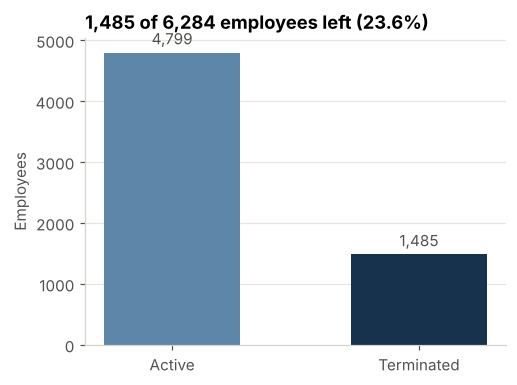

In [22]:
counts = df['status'].value_counts()

fig, ax = plt.subplots(figsize=(4.8, 3.6))
bars = ax.bar(counts.index, counts.values, color=[BLUE, ORANGE], width=0.55)
ax.bar_label(bars, labels=[f'{v:,}' for v in counts.values], padding=3, color=INK2)
ax.set_title(f"{counts['Terminated']:,} of {len(df):,} employees left ({df['left'].mean():.1%})")
ax.set_ylabel('Employees')
ax.grid(False); ax.grid(axis='y')
plt.tight_layout()
plt.show()

**Observation:** 1,485 of 6,284 employees (**23.6%**) left between 2006 and 2015.

**Important:** 23.6% is the **cumulative** share across ten years. It is *not* a yearly rate. Think of a school: "23.6% of everyone who ever attended has left" is very different from "about 3% leave each year". The yearly turnover rate is calculated in section 4.3.

## 4.2 Why do employees leave?

Only terminated employees have a reason, so I filter to them first with `df[df['status'] == 'Terminated']`. `value_counts()` then counts each reason and `normalize=True` turns the counts into shares.

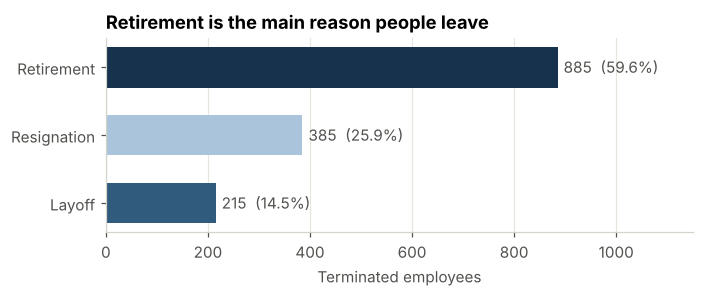

term_type
Voluntary      85.5
Involuntary    14.5
Name: proportion, dtype: float64


In [23]:
t = df[df['status'] == 'Terminated'].copy()

reason_counts = t['term_reason'].value_counts()
reason_pct = (reason_counts / reason_counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(6.5, 2.8))
bars = ax.barh(reason_counts.index, reason_counts.values,
               color=[REASON_COLORS[r] for r in reason_counts.index], height=0.6)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f'{n:,}  ({p}%)' for n, p in zip(reason_counts.values, reason_pct.values)],
             padding=4, color=INK2)
ax.set_xlim(0, reason_counts.max() * 1.3)
ax.set_title('Retirement is the main reason people leave')
ax.set_xlabel('Terminated employees')
ax.grid(False); ax.grid(axis='x')
plt.tight_layout()
plt.show()

print((t['term_type'].value_counts(normalize=True) * 100).round(1))

**Observation:**
- **Retirement** 885 (59.6%), **Resignation** 385 (25.9%), **Layoff** 215 (14.5%)
- **85.5%** of exits are *voluntary* (retirement + resignation) and 14.5% are *involuntary* (layoff)

So most "attrition" is people reaching retirement age, which HR can plan for. The exits worth investigating are **resignations** and **layoffs**.

## 4.3 When do they leave? Yearly trend

To follow the company over time I need, for each year:

| Measure | Meaning |
|---|---|
| `hires` | employees hired that year (from `hire_date`) |
| `exits` | employees who left that year (from `term_date`) |
| `headcount_year_end` | running total of hires minus exits, using `cumsum()` (cumulative sum) |
| `on_payroll` | employees on payroll during the year, counted from the **original yearly snapshots** (`raw`) |
| `turnover_pct` | exits / on_payroll x 100 (the true **yearly** attrition rate) |

`value_counts()` counts per year, and a `DataFrame` built from them lines the years up (missing years become 0).

**Two corrections to my first version:**
- I called the running total "retention", but it is really **headcount**, the number of people employed at year end.
- Years before 2006 are unreliable, because people who left *before* 2006 are not in this dataset. I only use **2006–2015**.

In [24]:
on_payroll = raw.groupby('STATUS_YEAR')['EmployeeID'].nunique()
hires = df['hire_date'].dt.year.value_counts()
exits = t['term_date'].dt.year.value_counts()

yearly = pd.DataFrame({'hires': hires, 'exits': exits}).fillna(0).astype(int).sort_index()
yearly['headcount_year_end'] = (yearly['hires'] - yearly['exits']).cumsum()
yearly = yearly.loc[2006:2015]
yearly['on_payroll'] = on_payroll
yearly['turnover_pct'] = (yearly['exits'] / yearly['on_payroll'] * 100).round(1)
yearly.index.name = 'year'

# cross-check: headcount from hires/exits must equal payroll count minus the people who left that year
print('headcount cross-check passes:', (yearly['on_payroll'] - yearly['exits'] == yearly['headcount_year_end']).all())
yearly.to_csv('yearly_summary.csv')
yearly

headcount cross-check passes: True


,hires,exits,headcount_year_end,on_payroll,turnover_pct
year,,,,,
2006,239,134,4445,4579,2.9
2007,237,162,4520,4682,3.5
2008,246,164,4602,4766,3.4
2009,249,142,4709,4851,2.9
2010,254,123,4840,4963,2.5
2011,242,110,4972,5082,2.2
2012,259,130,5101,5231,2.5
2013,218,105,5214,5319,2.0
2014,0,253,4961,5214,4.9


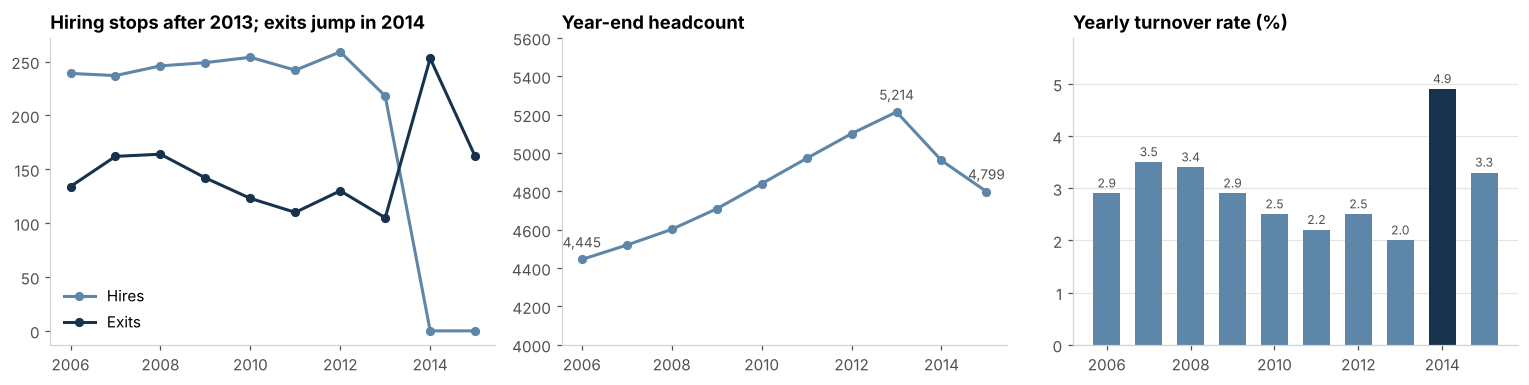

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

# hires vs exits
ax = axes[0]
ax.plot(yearly.index, yearly['hires'], color=BLUE, lw=2, marker='o', ms=5, label='Hires')
ax.plot(yearly.index, yearly['exits'], color=ORANGE, lw=2, marker='o', ms=5, label='Exits')
ax.set_xticks(yearly.index[::2]); ax.legend(frameon=False)
ax.set_title('Hiring stops after 2013; exits jump in 2014')

# headcount
ax = axes[1]
ax.plot(yearly.index, yearly['headcount_year_end'], color=BLUE, lw=2, marker='o', ms=5)
for yr in (2006, 2013, 2015):
    ax.annotate(f"{yearly.loc[yr, 'headcount_year_end']:,}", (yr, yearly.loc[yr, 'headcount_year_end']),
                textcoords='offset points', xytext=(0, 8), ha='center', color=INK2, fontsize=9)
ax.set_xticks(yearly.index[::2]); ax.set_ylim(4000, 5600)
ax.set_title('Year-end headcount')

# turnover rate
ax = axes[2]
top = yearly['turnover_pct'].idxmax()
bars = ax.bar(yearly.index, yearly['turnover_pct'], width=0.65,
              color=[ORANGE if y == top else BLUE for y in yearly.index])
ax.bar_label(bars, labels=[f'{v:.1f}' for v in yearly['turnover_pct']], padding=2, color=INK2, fontsize=8)
ax.set_xticks(yearly.index[::2]); ax.set_ylim(0, yearly['turnover_pct'].max() * 1.2)
ax.set_title('Yearly turnover rate (%)')
ax.grid(False); ax.grid(axis='y')

plt.tight_layout()
plt.show()

**Observation:**
- The **yearly** turnover rate is only about **2.0% to 4.9%**, so the 23.6% from section 4.1 is ten years added up.
- Turnover was falling (3.5% in 2007 to 2.0% in 2013), then **spiked to 4.9% in 2014** (253 exits).
- **No hires appear after 2013** in this data. Combined with the 2014–2015 exits, headcount fell from **5,214 (end of 2013) to 4,799 (end of 2015)**, down 8.0%.

### Exits per year, split by reason

Stacking the reasons shows *what* caused the 2014 spike. `pd.crosstab()` counts how many employees fall in each combination of year and reason.

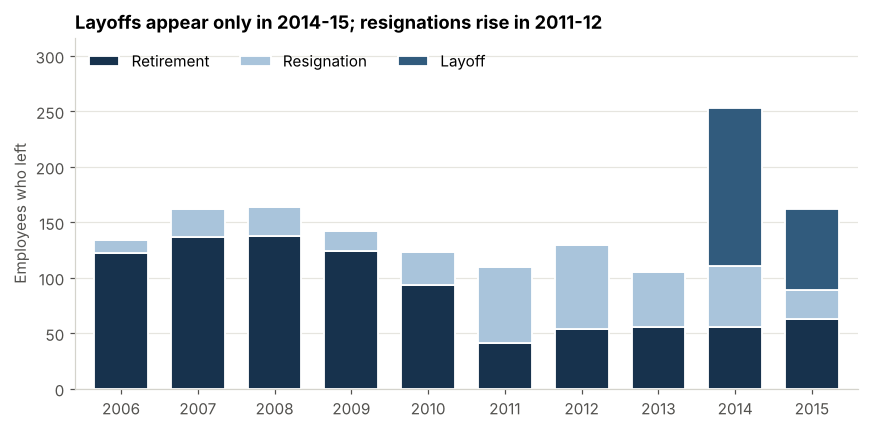

term_reason,Retirement,Resignation,Layoff
year,,,
2006,122,12,0
2007,137,25,0
2008,138,26,0
2009,124,18,0
2010,94,29,0
2011,41,69,0
2012,54,76,0
2013,56,49,0
2014,56,55,142


In [26]:
by_year = pd.crosstab(t['year'], t['term_reason'])[REASONS]

fig, ax = plt.subplots(figsize=(8, 4))
by_year.plot(kind='bar', stacked=True, ax=ax, color=[REASON_COLORS[r] for r in REASONS],
             width=0.7, edgecolor='white', linewidth=1.2)
ax.set_title('Layoffs appear only in 2014-15; resignations rise in 2011-12')
ax.set_xlabel(''); ax.set_ylabel('Employees who left')
ax.set_ylim(0, by_year.sum(axis=1).max() * 1.25)
ax.legend(frameon=False, ncol=3, loc='upper left')
plt.xticks(rotation=0)
ax.grid(False); ax.grid(axis='y')
plt.tight_layout()
plt.show()

by_year

**Observation:**
- **Layoffs:** zero from 2006 to 2013, then **142 in 2014** and **73 in 2015**. This explains the 2014 spike.
- **Resignations:** about 12–29 a year until 2010, then **69 in 2011 and 76 in 2012**, easing to 26 by 2015.
- **Retirements:** 94–138 a year until 2010, then only **41–63 a year** from 2011.

## 4.4 Where do they leave? Departments

I group by `department` and take the average of `left` to get each department's attrition rate. Tiny departments are misleading (3 of 4 people leaving looks like 75%), so the chart only shows departments with **at least 100 employees**. The full table is printed below it.

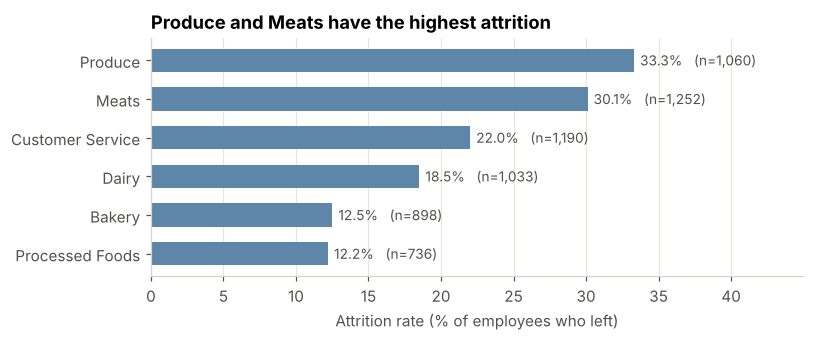

All departments (including the small ones):


,employees,left,rate
department,,,
Accounting,6,6,100.0
Accounts Payable,4,4,100.0
Accounts Receivable,5,5,100.0
Audit,4,4,100.0
Compensation,4,4,100.0
Investment,4,4,100.0
Employee Records,6,6,100.0
Information Technology,5,5,100.0
HR Technology,9,9,100.0


In [27]:
dept = rate_table('department', min_n=100).sort_values('rate', ascending=False)
rate_bar(dept, 'Produce and Meats have the highest attrition', horizontal=True, figsize=(7.5, 3.2))

print('All departments (including the small ones):')
rate_table('department').sort_values('rate', ascending=False)

**Observation:**
- **Produce (33.3%)** and **Meats (30.1%)** lose the most people, then Customer Service (22.0%) and Dairy (18.5%). Bakery and Processed Foods are lowest at about 12%.
- The small departments (Store Management, head-office teams) show very high rates (Store Management 88.6% of 35 people), but these groups are tiny and mostly retirements.

A high rate does not tell us *why* people left. The next chart splits each department's exits by reason.

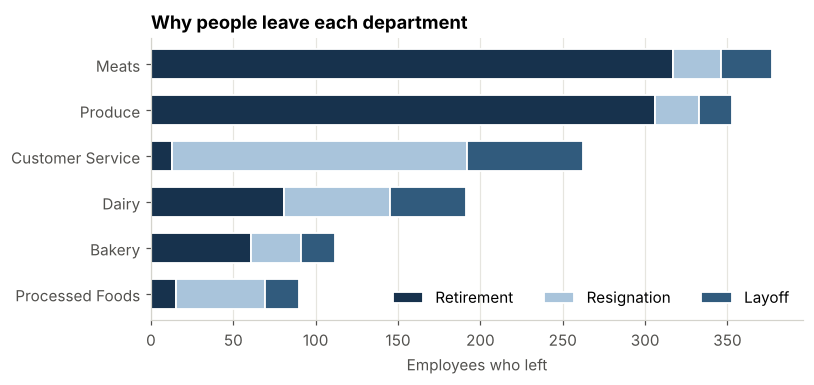

term_reason,Retirement,Resignation,Layoff
department,,,
Customer Service,13,179,70
Dairy,81,64,46
Processed Foods,15,54,21
Bakery,61,30,21
Meats,317,29,31
Produce,306,27,20


In [28]:
big = dept.index.tolist()
by_dept = pd.crosstab(t.loc[t['department'].isin(big), 'department'], t['term_reason'])[REASONS]
by_dept = by_dept.loc[by_dept.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
by_dept.plot(kind='barh', stacked=True, ax=ax, color=[REASON_COLORS[r] for r in REASONS],
             width=0.65, edgecolor='white', linewidth=1.2)
ax.set_title('Why people leave each department')
ax.set_ylabel(''); ax.set_xlabel('Employees who left')
ax.legend(frameon=False, ncol=3, loc='lower right')
ax.grid(False); ax.grid(axis='x')
plt.tight_layout()
plt.show()

by_dept.sort_values('Resignation', ascending=False)

**Observation:**
- **Produce and Meats are mostly retirements** (306 and 317). They have the highest rates because many of their employees were old, not because they are unhappy places to work.
- **Customer Service is the real retention problem**: 179 resignations (**46.5% of all resignations**) plus 70 layoffs, with almost no retirements.
- **Dairy** has the next-highest number of layoffs (46) after Customer Service.

## 4.5 Who leaves? Age, tenure and gender

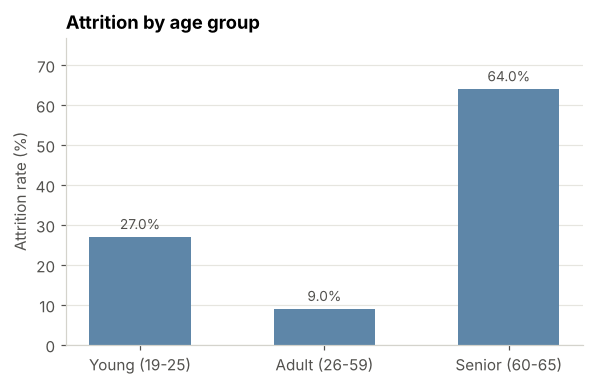

,employees,left,rate
age_group,,,
Young (19-25),736,199,27.0
Adult (26-59),4119,371,9.0
Senior (60-65),1429,915,64.0


In [29]:
age_t = rate_table('age_group')
rate_bar(age_t, 'Attrition by age group', figsize=(5.5, 3.6))
age_t

**Observation:**
- **Senior (60–65): 64.0%.** These are almost all retirements. Every retirement in the data happens at exactly age 60 or 65, which looks rule-based.
- **Young (19–25): 27.0%** have left, compared with only **9.0%** of Adults (26–59). Early-career employees are the group most likely to leave by choice or be let go.

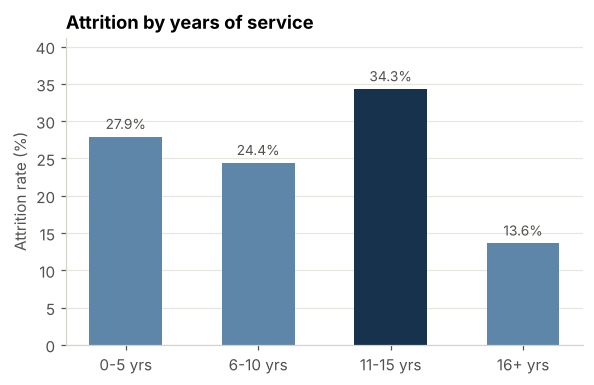

,employees,left,rate
tenure_group,,,
0-5 yrs,1113,310,27.9
6-10 yrs,1346,328,24.4
11-15 yrs,1580,542,34.3
16+ yrs,2245,305,13.6


In [30]:
ten_t = rate_table('tenure_group')
rate_bar(ten_t, 'Attrition by years of service', figsize=(5.5, 3.6), hi=['11-15 yrs'])
ten_t

**Observation:** attrition is **27.9%** in the first 5 years, dips to 24.4% for years 6–10, peaks at **34.3% at 11–15 years** (the retirement wave, since typical retirees have about 13 years of service), then drops to 13.6% for 16+ years.

Now, who resigns? A box plot shows the spread of age and tenure for each exit reason. The box is the middle 50% of people, the line inside is the median.

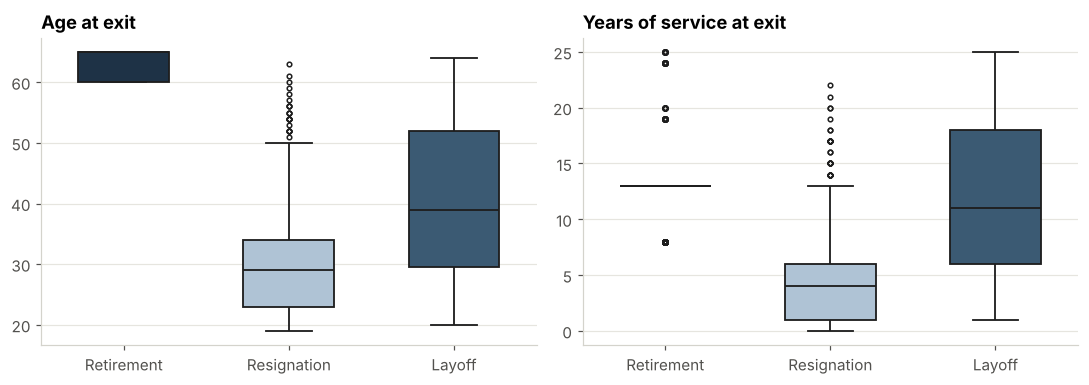

,age,tenure
term_reason,,
Layoff,39.0,11.0
Resignation,29.0,4.0
Retirement,65.0,13.0


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, title in zip(axes, ['age', 'tenure'], ['Age at exit', 'Years of service at exit']):
    sns.boxplot(data=t, x='term_reason', y=col, order=REASONS, hue='term_reason', palette=REASON_COLORS,
                legend=False, ax=ax, width=0.55, linewidth=1.2, fliersize=3)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('')
    ax.grid(False); ax.grid(axis='y')
plt.tight_layout()
plt.show()

t.groupby('term_reason')[['age', 'tenure']].median()

**Observation:** the typical resigner is about **29 years old with 4 years of service**. Layoffs hit mid-career people (median age 39, 11 years of service). Retirees are 60–65 with about 13 years of service.

### Gender

Women make up 52.2% of the employees. Next I compare attrition for each gender, then break it down by reason to see *where* any gap comes from.

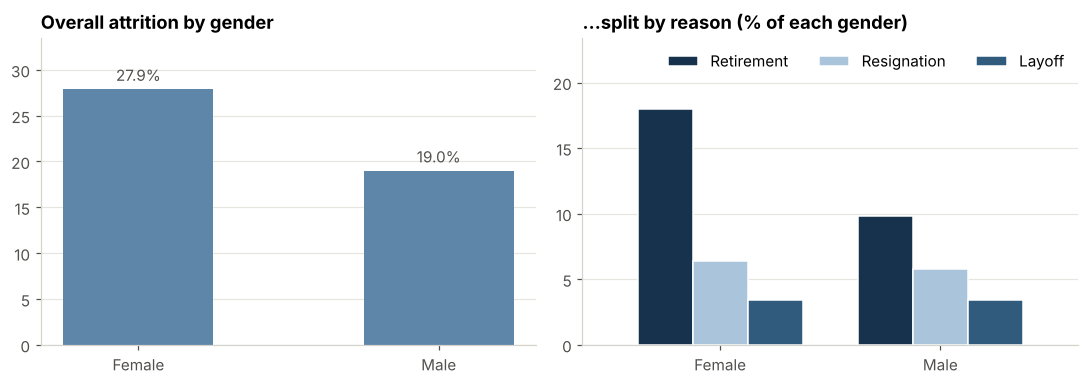

term_reason  Layoff  Still active  Resignation  Retirement
gender                                                    
Female          3.4          72.1          6.4        18.0
Male            3.4          81.0          5.8         9.8

gender
Female    46.0
Male      43.4
Name: average age, dtype: float64


In [32]:
g_t = rate_table('gender')
reason_by_gender = (pd.crosstab(df['gender'], df['term_reason'], normalize='index') * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

ax = axes[0]
bars = ax.bar(g_t.index, g_t['rate'], color='#5E86A8', width=0.5)
ax.bar_label(bars, labels=[f'{r:.1f}%' for r in g_t['rate']], padding=3, color=INK2)
ax.set_ylim(0, g_t['rate'].max() * 1.2)
ax.set_title('Overall attrition by gender')
ax.grid(False); ax.grid(axis='y')

ax = axes[1]
reason_by_gender[REASONS].plot(kind='bar', ax=ax, color=[REASON_COLORS[r] for r in REASONS],
                               width=0.75, edgecolor='white', linewidth=1)
ax.set_title('...split by reason (% of each gender)')
ax.set_xlabel(''); plt.setp(ax.get_xticklabels(), rotation=0)
ax.legend(frameon=False, ncol=3, loc='upper right')
ax.set_ylim(0, reason_by_gender[REASONS].values.max() * 1.3)
ax.grid(False); ax.grid(axis='y')

plt.tight_layout()
plt.show()

print(reason_by_gender.rename(columns={'Not Applicable': 'Still active'}))
print()
print(df.groupby('gender')['age'].mean().round(1).rename('average age'))

**Observation:**
- Women left at **27.9%** versus **19.0%** for men.
- The gap is almost entirely **retirement**: 18.0% of women retired versus 9.8% of men. Resignation (6.4% vs 5.8%) and layoffs (3.4% each) are almost equal.
- Women in this data are also older on average (46.0 vs 43.4).

This should **not** be read as "women are treated worse". It points to an age and retirement effect that needs a closer look before drawing any conclusion about gender.

## 4.6 Layoffs: where did they happen?

142 of the 215 layoffs happened in 2014. Which cities were hit?

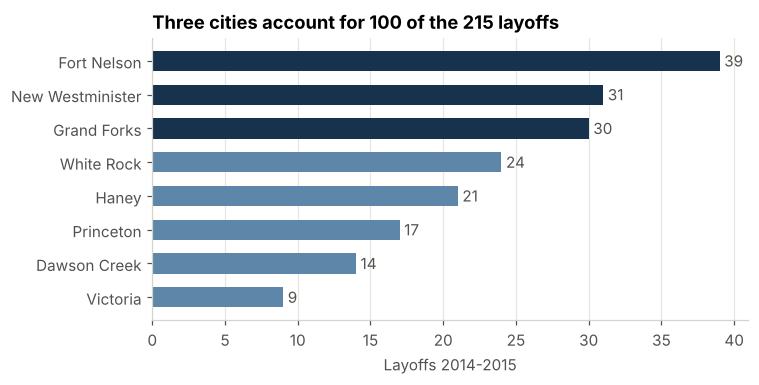

Top 3 cities: layoffs by year
city              year
Fort Nelson       2014    39
Grand Forks       2014    30
New Westminister  2014    31
dtype: int64

Share of ALL employees in these cities who left:
                  employees  left_share
city                                   
Fort Nelson              47         1.0
Grand Forks              33         1.0
New Westminister         44         1.0


In [33]:
lay = t[t['term_reason'] == 'Layoff']
by_city = lay.groupby('city').size().sort_values(ascending=False).head(8)
top3 = by_city.index[:3]

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(by_city.index, by_city.values, height=0.6,
               color=[ORANGE if c in top3 else BLUE for c in by_city.index])
ax.invert_yaxis()
ax.bar_label(bars, padding=3, color=INK2)
ax.set_title('Three cities account for 100 of the 215 layoffs')
ax.set_xlabel('Layoffs 2014-2015')
ax.grid(False); ax.grid(axis='x')
plt.tight_layout()
plt.show()

print('Top 3 cities: layoffs by year')
print(lay[lay['city'].isin(top3)].groupby(['city', 'year']).size())
print()
print('Share of ALL employees in these cities who left:')
print(df[df['city'].isin(top3)].groupby('city')['left'].agg(employees='size', left_share='mean'))

**Observation:** **Fort Nelson (39), New Westminister (31) and Grand Forks (30)** account for 100 of the 215 layoffs. All of them happened in 2014, and in each of these three locations **100% of employees have left**: whoever was still working there in 2014 was laid off. The data does not say why, but a whole location going to zero looks like **store closures**.

(`New Westminister` is the misspelled name of store 20, which is separate from the larger `New Westminster` store 21; see section 3.4.)

The other cities with layoffs (White Rock, Haney, Princeton, Dawson Creek) had between 14 and 24 layoffs each.

## 4.7 Distributions and correlation

### Age and tenure distributions
`histplot()` counts how many employees fall into each age or tenure value.

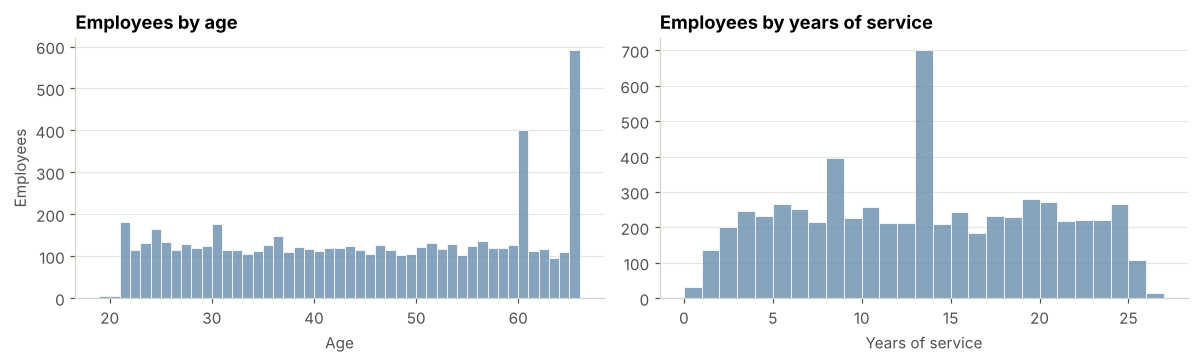

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(df['age'], bins=range(19, 67), color=BLUE, ax=axes[0], edgecolor='white', linewidth=0.5)
axes[0].set_title('Employees by age'); axes[0].set_xlabel('Age'); axes[0].set_ylabel('Employees')
sns.histplot(df['tenure'], bins=range(0, 28), color=BLUE, ax=axes[1], edgecolor='white', linewidth=0.5)
axes[1].set_title('Employees by years of service'); axes[1].set_xlabel('Years of service'); axes[1].set_ylabel('')
for ax in axes:
    ax.grid(False); ax.grid(axis='y')
plt.tight_layout()
plt.show()

**Observation:** ages run from 19 to 65. Employees are spread fairly evenly from the 20s to the 50s, with a **tall spike at 60 and 65**, the two retirement ages. Years of service run from 0 to 26.

### Correlation
Correlation measures how strongly two numeric columns move together (+1 = together, -1 = opposite, 0 = unrelated). I use only `age`, `tenure` and `left`.

I leave out `id` and `year` on purpose. Employee IDs were assigned in hiring order, so `id` correlates strongly with age and tenure just by construction. That says nothing about attrition.

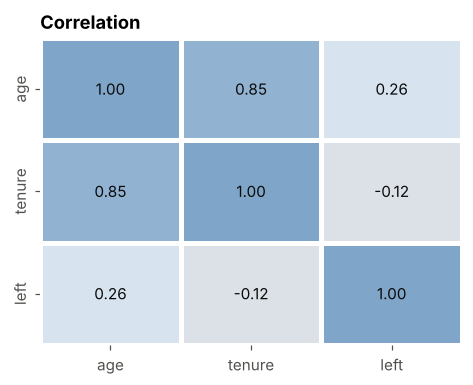

In [35]:
corr = df[['age', 'tenure', 'left']].corr()
div = LinearSegmentedColormap.from_list('div', ['#17324D', '#F7F9FC', '#7FA6C9'])

fig, ax = plt.subplots(figsize=(4.4, 3.6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=div, vmin=-1, vmax=1, ax=ax, linewidths=2,
            linecolor='white', cbar=False, annot_kws={'color': INK})
ax.set_title('Correlation')
plt.tight_layout()
plt.show()

**Observation:**
- Age and tenure move together strongly (**0.85**): older employees have more years of service.
- Leaving is only weakly linked to age (**0.26**) and tenure (**-0.12**).

That weak number is misleading. Correlation only detects *straight-line* patterns, and attrition here is **U-shaped**: young employees (27.0%) and seniors (64.0%) leave, while the middle (9.0%) stays. The group rates in section 4.5 describe it much better than one correlation number.

Correlation is not causation. This only describes what happens together.

## 4.8 Outlier check (box plot and the IQR rule)

An **outlier** is a value far away from the rest. The box plot uses the **IQR rule**:

1. Sort the values; **Q1** = the value 25% of the way up, **Q2** = the median, **Q3** = 75% of the way up
2. **IQR = Q3 - Q1** (the spread of the middle half)
3. Lower fence = `Q1 - 1.5 x IQR`; upper fence = `Q3 + 1.5 x IQR`
4. Anything outside the fences is an outlier

*Small example:* for `[1, 10, 203, 210, 215, 220, 225, 255, 272, 900, 990]`, pandas gives Q1 = 206.5 and Q3 = 263.5, so IQR = 57 and the fences are 121 and 349. The values `1, 10, 900, 990` fall outside them, so they are outliers. The function below checks this and then runs on the real columns.

There are no missing values in this dataset, so the useful check is for strange values. Mean and median close together also mean the data is roughly **symmetric**: if values had been missing, filling them with the mean would have been reasonable.

In [36]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'mean': s.mean().round(1), 'median': s.median(), 'Q1': q1, 'Q3': q3,
                      'lower fence': low, 'upper fence': high,
                      'outliers': int(((s < low) | (s > high)).sum())})

# the small example from the text
iqr_outliers(pd.Series([1, 10, 203, 210, 215, 220, 225, 255, 272, 900, 990]))

mean           318.3
median         220.0
Q1             206.5
Q3             263.5
lower fence    121.0
upper fence    349.0
outliers         4.0
dtype: float64

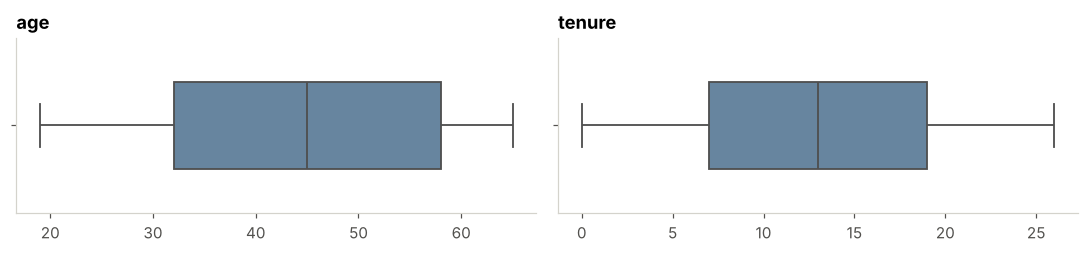

,age,tenure
mean,44.7,12.8
median,45.0,13.0
Q1,32.0,7.0
Q3,58.0,19.0
lower fence,-7.0,-11.0
upper fence,97.0,37.0
outliers,0.0,0.0


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.4))
for ax, col in zip(axes, ['age', 'tenure']):
    sns.boxplot(data=df, x=col, color=BLUE, ax=ax, width=0.5, linewidth=1.2)
    ax.set_title(col); ax.set_xlabel('')
plt.tight_layout()
plt.show()

pd.DataFrame({c: iqr_outliers(df[c]) for c in ['age', 'tenure']})

**Observation:** `age` and `tenure` have **zero outliers**, and their mean and median are almost equal (45 vs 45 for age, 12.8 vs 13 for tenure), so both are roughly symmetric. If values had been missing, filling them with the mean would have been reasonable. No cleaning is needed here.

# 5. Conclusion

## Key findings

| # | Finding | Evidence |
|---|---|---|
| 1 | **1,485 of 6,284 employees (23.6%) left in 2006–2015**, but yearly turnover is only **2.0–4.9%** | Sections 4.1 and 4.3 |
| 2 | **Retirement is the biggest reason (59.6%)**, followed by resignation (25.9%) and layoff (14.5%); 85.5% of exits are voluntary | Section 4.2 |
| 3 | **2014 was an outlier year** (4.9% turnover, 253 exits). **Layoffs started in 2014** (142, then 73 in 2015) and hiring stopped after 2013, so headcount fell 8.0% from 5,214 to 4,799 | Section 4.3 |
| 4 | **100 of the 215 layoffs came from three locations** (Fort Nelson, New Westminister store 20, Grand Forks), where all remaining staff were let go in 2014, which looks like store closures | Section 4.6 |
| 5 | **Customer Service has the real retention problem**: 179 resignations (46.5% of all resignations) plus 70 layoffs | Section 4.4 |
| 6 | **Produce and Meats have the highest attrition (33.3% and 30.1%)** because of retirements (623 of 885 retirements) | Section 4.4 |
| 7 | **Early-career employees leave more**: 27.0% of ages 19–25 vs 9.0% of ages 26–59; the typical resigner is 29 with 4 years of service | Section 4.5 |
| 8 | Women left more often than men (27.9% vs 19.0%), but the gap is almost all **retirement** and not a sign of unequal treatment on its own | Section 4.5 |
| 9 | Resignations jumped to 69 and 76 in 2011–12 while retirements dropped to about 40–60 a year | Section 4.3 |

## Recommendations

1. **Investigate Customer Service retention.** Look at pay, workload and career paths in the first 5 years, since this is where most resignations and a large share of layoffs sit.
2. **Plan for retirements in Meats and Produce.** More than 85% of their exits (623 of 730) are retirements, so build succession plans and train replacements early.
3. **Review the 2014–15 layoff decisions** (store closures and which departments were cut), and check why no hiring is recorded after 2013.
4. **Look into the 2011–12 resignation jump** with exit interviews or engagement surveys if that period is still relevant.

## Limitations

- The data only covers **2006–2015**. Employees who left before 2006 are not included, and no hires are recorded after 2013.
- Each employee is counted once (latest record). Rates for **small groups** (head-office teams, small cities) are unreliable.
- There is **no data on salary, performance or job satisfaction**, so I can describe *who* and *when* but cannot prove *why* people resign.
- Correlation is not causation, and the gender gap needs an age-adjusted comparison before any conclusion.

## Next steps

- Build a **Power BI dashboard** from `Attrition_cleaned.csv` and `yearly_summary.csv` (attrition rate, reason, department and year slicers).
- Build a simple **prediction model** (for example logistic regression) to see which factors best predict resignation.